## Imports ##

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Reproductibilité
np.random.seed(42)


## Chargement dataset ##

In [2]:
df = pd.read_csv('Données/lamme_training.csv')
print(f"Dimensions : {df.shape}")
df.head()

Dimensions : (444, 30)


,Gene1,Gene2,Family_Size,Classification,PPI_Interactant_G1,PPI_Interactant_G2,PPI_Intersection,PPI_Union,PPI_Jaccard,Pfam_G1,...,TE_Coverage_G1,TE_Density_G1,TE_Number_G1,TE_Coverage_G2,TE_Density_G2,TE_Number_G2,TE_Env_G1,TE_Env_G2,TE_Env_Pair,TE_Env_Class
0,AT1G01030,AT2G46870,4,1.0,6.0,4.0,1.0,9.0,11.111111,1.0,...,1.318826,0.167056,1.0,5.777292,0.193424,1.0,TE-free,TE-free,TE-free_TE-free,free
1,AT1G01030,AT4G01500,4,1.0,11.0,4.0,1.0,14.0,7.142857,1.0,...,1.318826,0.167056,1.0,29.346681,0.745712,3.0,TE-rich,TE-free,TE-free_TE-rich,half
2,AT1G01060,AT2G46830,2,0.0,23.0,21.0,12.0,32.0,37.500000,1.0,...,0.000000,0.000000,0.0,0.000000,0.000000,0.0,TE-free,TE-free,TE-free_TE-free,free
3,AT1G01120,AT1G04220,17,1.0,8.0,7.0,1.0,14.0,7.142857,3.0,...,15.273775,0.200080,1.0,0.000000,0.000000,0.0,TE-free,TE-poor,TE-free_TE-poor,half
4,AT1G01120,AT4G34520,17,1.0,0.0,7.0,0.0,7.0,NaN,3.0,...,15.273775,0.200080,1.0,0.000000,0.000000,0.0,TE-free,TE-poor,TE-free_TE-poor,half


In [3]:
print("=== Types de colonnes ===")
print(df.dtypes)

=== Types de colonnes ===
Gene1                     str
Gene2                     str
Family_Size             int64
Classification        float64
PPI_Interactant_G1    float64
PPI_Interactant_G2    float64
PPI_Intersection      float64
PPI_Union             float64
PPI_Jaccard           float64
Pfam_G1               float64
Pfam_G2               float64
Pfam_Inter            float64
Pfam_Union            float64
Pfam_Jaccard          float64
Ks                    float64
Ka                    float64
Ka_Ks                 float64
Ks_SD                 float64
Ka_SD                 float64
Distance              float64
TE_Coverage_G1        float64
TE_Density_G1         float64
TE_Number_G1          float64
TE_Coverage_G2        float64
TE_Density_G2         float64
TE_Number_G2          float64
TE_Env_G1                 str
TE_Env_G2                 str
TE_Env_Pair               str
TE_Env_Class              str
dtype: object


/tmp/ipykernel_1657/1742320721.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Family_Size', data=df, palette='Set2')


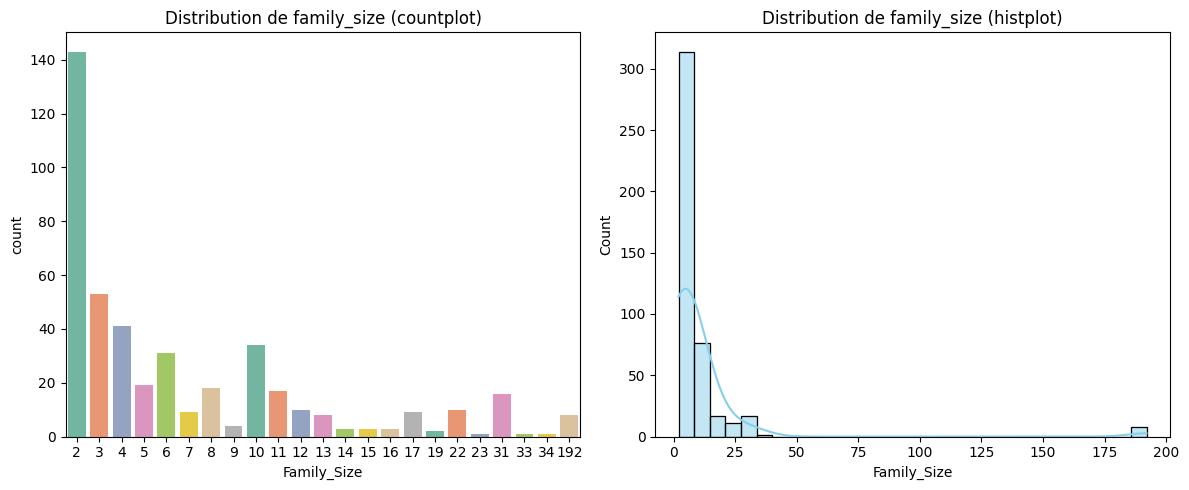

In [4]:
# Représentation de la distribution de family_size de 2 manières différentes : countplot et histplot
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.countplot(x='Family_Size', data=df, palette='Set2')
plt.title('Distribution de family_size (countplot)')
plt.subplot(1, 2, 2)
sns.histplot(df['Family_Size'], bins=30, kde=True, color='skyblue')
plt.title('Distribution de family_size (histplot)')
plt.tight_layout()
plt.savefig('Plots/lamme_training/family_size_distribution.png', dpi=300)
plt.show()

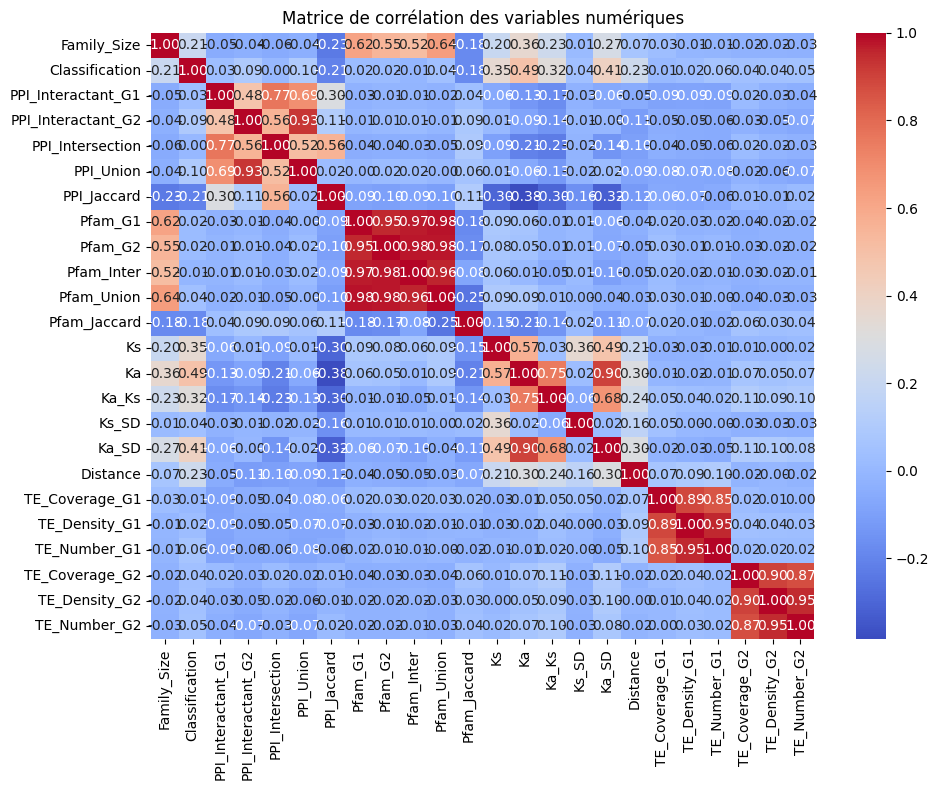

In [5]:
# Matrice de corrélation pour les variables numériques par rapport à la variable cible qui est classification
numeric_cols = [
    'Family_Size',
    'PPI_Interactant_G1', 'PPI_Interactant_G2', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard',
    'Pfam_G1', 'Pfam_G2', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard',
    'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance',
    'TE_Coverage_G1', 'TE_Density_G1', 'TE_Number_G1',
    'TE_Coverage_G2', 'TE_Density_G2', 'TE_Number_G2'
]

plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matrice de corrélation des variables numériques')
plt.tight_layout()
plt.savefig('Plots/lamme_training/correlation_matrix.png', dpi=300)
plt.show()

In [6]:
print("\n=== Valeurs manquantes ===")
missing = df.isnull().sum()
print(missing[missing > 0])


=== Valeurs manquantes ===
PPI_Jaccard     166
Pfam_Jaccard      7
Distance         63
dtype: int64


In [7]:
print("\n=== Distribution de Classification ===")
print(df['Classification'].value_counts())


=== Distribution de Classification ===
Classification
1.0    262
0.0    182
Name: count, dtype: int64


In [8]:
print("\n=== Distribution de TE_Env_Class ===")
print(df['TE_Env_Class'].value_counts())


=== Distribution de TE_Env_Class ===
TE_Env_Class
free    281
half    151
rich     12
Name: count, dtype: int64


In [9]:
df.drop(columns=['Classification', 'TE_Env_Class']).describe()

,Family_Size,PPI_Interactant_G1,PPI_Interactant_G2,PPI_Intersection,PPI_Union,PPI_Jaccard,Pfam_G1,Pfam_G2,Pfam_Inter,Pfam_Union,...,Ka_Ks,Ks_SD,Ka_SD,Distance,TE_Coverage_G1,TE_Density_G1,TE_Number_G1,TE_Coverage_G2,TE_Density_G2,TE_Number_G2
count,444.000000,444.000000,444.000000,444.000000,444.000000,278.000000,444.000000,444.000000,444.000000,444.000000,...,444.000000,444.000000,444.000000,381.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000
mean,10.252252,10.488739,13.211712,4.664414,19.036036,25.284498,2.644144,2.601351,2.430180,2.815315,...,0.193110,3.849980,0.021308,0.338344,5.435983,0.177642,1.000000,5.691311,0.190079,1.031532
std,25.587885,19.742984,29.326838,14.294942,33.319624,28.108272,3.033215,2.862712,2.512648,3.372594,...,0.118174,66.671596,0.015181,0.200586,9.271440,0.346412,1.645844,9.312470,0.353046,1.615080
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.010800,0.000000,0.013329,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,1.000000,0.000000,0.000000,2.000000,3.114144,1.000000,1.000000,1.000000,1.000000,...,0.102773,0.107925,0.010600,0.188154,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.000000,4.000000,4.000000,0.000000,8.000000,16.666667,2.000000,2.000000,2.000000,2.000000,...,0.169878,0.235950,0.016550,0.296972,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,10.000000,12.000000,13.250000,4.000000,21.000000,36.201299,3.000000,3.000000,3.000000,3.000000,...,0.263050,0.487825,0.026825,0.452873,8.289697,0.219335,2.000000,8.749726,0.211909,1.000000
max,192.000000,160.000000,305.000000,133.000000,308.000000,100.000000,22.000000,20.000000,17.000000,24.000000,...,0.644444,1405.141600,0.102400,0.999962,58.680788,2.920182,12.000000,52.213353,2.661344,12.000000


## Preprocessing des variables ##

In [10]:
from sklearn.preprocessing import OneHotEncoder

# --- Features numériques continues ---
numeric_features = [
    'Family_Size',
    'PPI_Interactant_G1', 'PPI_Interactant_G2', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard',
    'Pfam_G1', 'Pfam_G2', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard',
    'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance',
    'TE_Coverage_G1', 'TE_Density_G1', 'TE_Number_G1',
    'TE_Coverage_G2', 'TE_Density_G2', 'TE_Number_G2'
]

# Features catégorielles à encoder
# Classification et TE_Env_Class sont des labels → exclus des features
cat_features = ['TE_Env_G1', 'TE_Env_G2', 'TE_Env_Pair']


# One-Hot Encoding des catégorielles
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_cat = ohe.fit_transform(df[cat_features])

# Noms des colonnes OHE (ex: TE_Env_G1_TE-free, TE_Env_G1_TE-rich, ...)
cat_col_names = ohe.get_feature_names_out(cat_features).tolist()

all_features = numeric_features + cat_col_names

print(f"Features numériques : {len(numeric_features)}")
print(f"Features OHE        : {len(cat_col_names)}  → {cat_col_names}")
print(f"Nombre total de features utilisées : {len(all_features)}")
print(all_features)

Features numériques : 23
Features OHE        : 12  → ['TE_Env_G1_TE-free', 'TE_Env_G1_TE-poor', 'TE_Env_G1_TE-rich', 'TE_Env_G2_TE-free', 'TE_Env_G2_TE-poor', 'TE_Env_G2_TE-rich', 'TE_Env_Pair_TE-free_TE-free', 'TE_Env_Pair_TE-free_TE-poor', 'TE_Env_Pair_TE-free_TE-rich', 'TE_Env_Pair_TE-poor_TE-poor', 'TE_Env_Pair_TE-poor_TE-rich', 'TE_Env_Pair_TE-rich_TE-rich']
Nombre total de features utilisées : 35
['Family_Size', 'PPI_Interactant_G1', 'PPI_Interactant_G2', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_G1', 'Pfam_G2', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_G1', 'TE_Density_G1', 'TE_Number_G1', 'TE_Coverage_G2', 'TE_Density_G2', 'TE_Number_G2', 'TE_Env_G1_TE-free', 'TE_Env_G1_TE-poor', 'TE_Env_G1_TE-rich', 'TE_Env_G2_TE-free', 'TE_Env_G2_TE-poor', 'TE_Env_G2_TE-rich', 'TE_Env_Pair_TE-free_TE-free', 'TE_Env_Pair_TE-free_TE-poor', 'TE_Env_Pair_TE-free_TE-rich', 'TE_Env_Pair_TE-poor_TE-poor', 'TE_Env_Pair_TE-p

In [11]:
X_cat = ohe.fit_transform(df[cat_features])

# Imputation des valeurs manquantes par la médiane, voir d'autres méthodes d'imputation si nécessaire
imputer = SimpleImputer(strategy='median')
X_num = imputer.fit_transform(df[numeric_features])

X_combined = np.hstack([X_num, X_cat])

# Standardisation nécéssaire pour t-SNE, met toutes les features à la même échelle
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_combined)

print(f"Matrice finale : {X_scaled.shape}")
print(f"Moyenne ≈ {X_scaled.mean():.4f}, Écart-type ≈ {X_scaled.std():.4f}")

Matrice finale : (444, 35)
Moyenne ≈ -0.0000, Écart-type ≈ 1.0000


## PCA ##

Composantes PCA retenues : 17
Variance expliquée cumulée : 96.2%


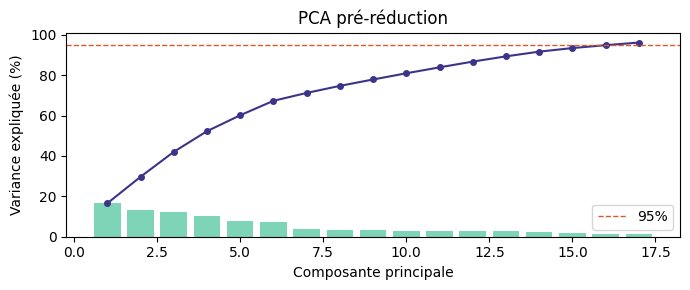

In [12]:
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_scaled)

cumvar = np.cumsum(pca.explained_variance_ratio_)
n_components_kept = X_pca.shape[1]
print(f"Composantes PCA retenues : {n_components_kept}")
print(f"Variance expliquée cumulée : {cumvar[-1]*100:.1f}%")

# Visualisation de la variance expliquée
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(1, n_components_kept+1), pca.explained_variance_ratio_*100, color='#5DCAA5', alpha=0.8)
ax.plot(range(1, n_components_kept+1), cumvar*100, 'o-', color='#3C3489', ms=4)
ax.axhline(95, ls='--', color='#D85A30', lw=1, label='95%')
ax.set_xlabel('Composante principale')
ax.set_ylabel('Variance expliquée (%)')
ax.set_title('PCA pré-réduction')
ax.legend()
plt.tight_layout()
plt.savefig('Plots/lamme_training/pca_variance_explained.png', dpi=300)
plt.show()

Variance expliquée par les 2 composantes : 29.7%


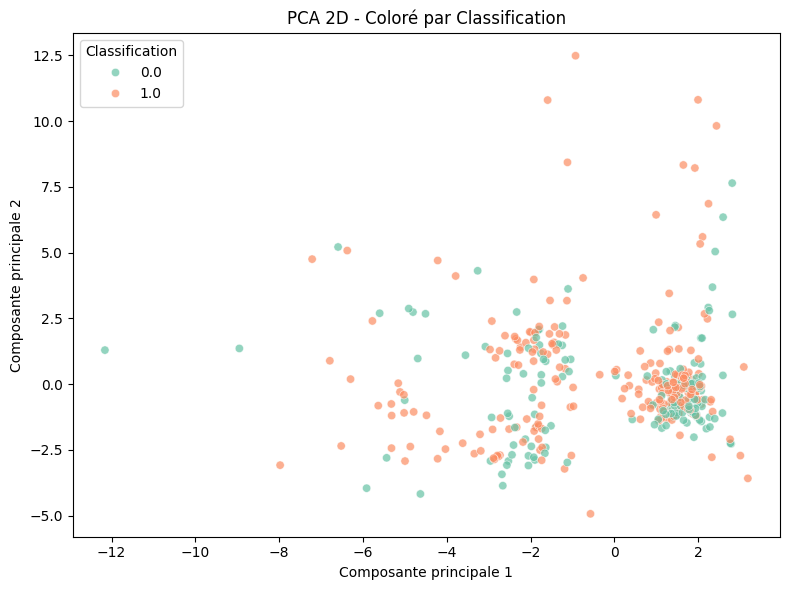

In [13]:
# Pca avec 2 composantes pour visualisation, pour voir si les classes sont séparables dans un espace 2D
pca_2 = PCA(n_components=2, random_state=42)
X_pca_2 = pca_2.fit_transform(X_scaled)
print(f"Variance expliquée par les 2 composantes : {pca_2.explained_variance_ratio_.sum()*100:.1f}%")   
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca_2[:, 0], y=X_pca_2[:, 1], hue=df['Classification'], palette='Set2', alpha=0.7)
plt.title('PCA 2D - Coloré par Classification')
plt.xlabel('Composante principale 1')
plt.ylabel('Composante principale 2')
plt.legend(title='Classification')
plt.tight_layout()
plt.savefig('Plots/lamme_training/pca_2d_classification.png', dpi=300)
plt.show()

## t-SNE ##

In [14]:
# t-SNE avec les composantes PCA pour réduire le bruit et accélérer le calcul
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    max_iter=1000,
    init='pca',
    random_state=42,
    n_jobs=-1
)

# Ajustement du modèle t-SNE sur les données PCA réduites
X_tsne = tsne.fit_transform(X_pca)

df_tsne = pd.DataFrame(X_tsne, columns=['tSNE_1', 'tSNE_2'])
df_tsne['Classification'] = df['Classification'].values.astype(int)
df_tsne['TE_Env_Class']   = df['TE_Env_Class'].values
df_tsne['Gene1']          = df['Gene1'].values
df_tsne['Gene2']          = df['Gene2'].values

print(f"KL divergence finale : {tsne.kl_divergence_:.4f}")
print(df_tsne.head())

KL divergence finale : 0.4619
      tSNE_1     tSNE_2  Classification TE_Env_Class      Gene1      Gene2
0  16.540627  -3.085294               1         free  AT1G01030  AT2G46870
1  -7.639694 -21.235706               1         half  AT1G01030  AT4G01500
2  14.391536  -7.911883               0         free  AT1G01060  AT2G46830
3 -28.941353   9.329475               1         half  AT1G01120  AT1G04220
4 -30.102982   5.066165               1         half  AT1G01120  AT4G34520


## Visualisation t-SNE ##

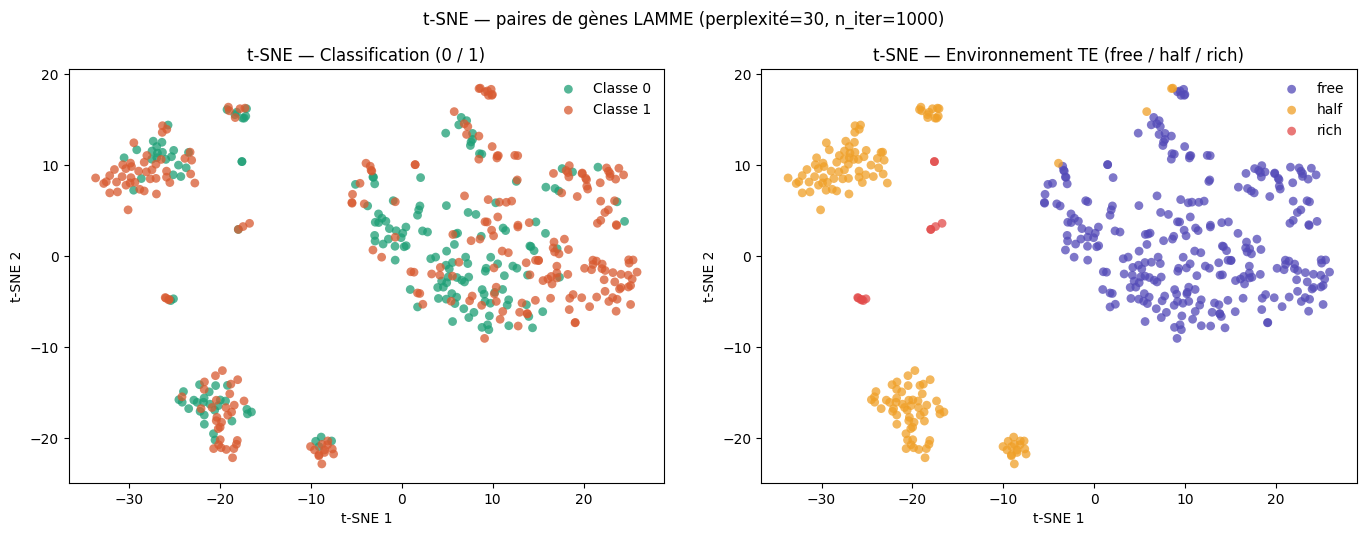

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Coloration par Classification (0 = non-dupliqué, 1 = dupliqué)
colors_clf = {0: '#1D9E75', 1: '#D85A30'}
labels_clf  = {0: 'Classe 0', 1: 'Classe 1'}
for cls, grp in df_tsne.groupby('Classification'):
    axes[0].scatter(
        grp['tSNE_1'], grp['tSNE_2'],
        c=colors_clf[cls], label=labels_clf[cls],
        alpha=0.75, s=40, edgecolors='none'
    )
axes[0].set_title('t-SNE — Classification (0 / 1)')
axes[0].set_xlabel('t-SNE 1')
axes[0].set_ylabel('t-SNE 2')
axes[0].legend(frameon=False)
axes[0].set_aspect('equal')

# Coloration par TE_Env_Class (free / half / rich)
palette_te = {'free': '#534AB7', 'half': '#EF9F27', 'rich': '#E24B4A'}
for env, grp in df_tsne.groupby('TE_Env_Class'):
    axes[1].scatter(
        grp['tSNE_1'], grp['tSNE_2'],
        c=palette_te[env], label=env,
        alpha=0.75, s=40, edgecolors='none'
    )
axes[1].set_title('t-SNE — Environnement TE (free / half / rich)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].legend(frameon=False)
axes[1].set_aspect('equal')

plt.suptitle('t-SNE — paires de gènes LAMME (perplexité=30, n_iter=1000)', y=1.02)
plt.tight_layout()
plt.savefig('Plots/lamme_training/tsne.png', dpi=150, bbox_inches='tight')
plt.show()

## Analyse perplexité ##

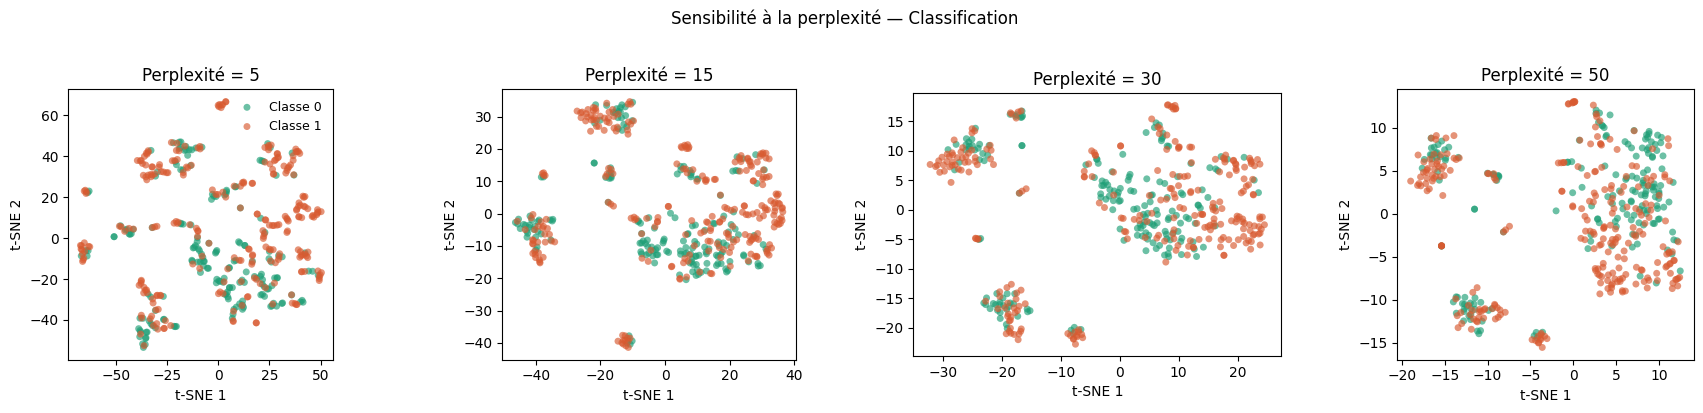

In [16]:
perplexities = [5, 15, 30, 50]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, perp in zip(axes, perplexities):
    emb = TSNE(
        n_components=2, perplexity=perp,
        learning_rate='auto', max_iter=800,
        init='pca', random_state=42
    ).fit_transform(X_pca)

    for cls in [0, 1]:
        mask = df['Classification'].values == cls
        ax.scatter(
            emb[mask, 0], emb[mask, 1],
            c=colors_clf[cls], alpha=0.65, s=25, edgecolors='none',
            label=labels_clf[cls]
        )
    ax.set_title(f'Perplexité = {perp}')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.set_aspect('equal')

axes[0].legend(frameon=False, fontsize=9)
plt.suptitle('Sensibilité à la perplexité — Classification', y=1.02)
plt.tight_layout()
plt.savefig('Plots/lamme_training/tsne_perplexity.png', dpi=150, bbox_inches='tight')
plt.show()

## Overlay d'une feature numérique

On superpose une variable continue sur la carte t-SNE pour voir
comment elle se structure dans l'espace réduit.

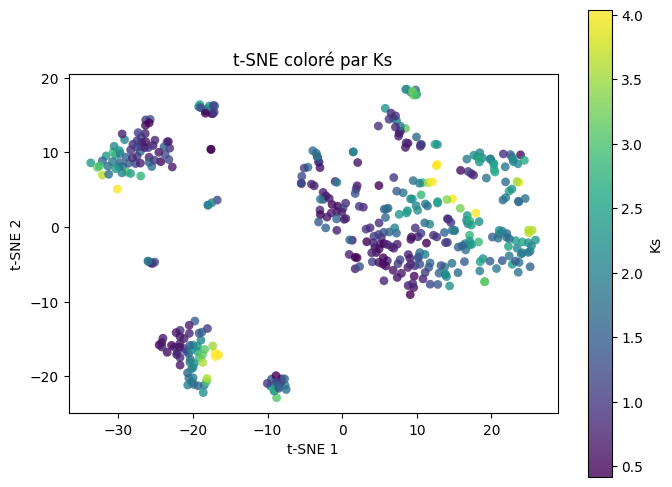

In [17]:
# Variables intéressantes à explorer : 'Ks', 'Ka_Ks', 'PPI_Jaccard', 'Distance'
feature_to_overlay = 'Ks'

vals = df[feature_to_overlay].values
# Clip aux percentiles 2-98 pour éviter que des outliers écrasent le colormap
vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(
    df_tsne['tSNE_1'], df_tsne['tSNE_2'],
    c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
    alpha=0.8, s=40, edgecolors='none'
)
plt.colorbar(sc, ax=ax, label=feature_to_overlay)
ax.set_title(f't-SNE coloré par {feature_to_overlay}')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

## Exportation des données t-SNE ##

In [18]:
# On reconstruit un dataframe complet avec les coordonnées t-SNE
df_out = df[['Gene1', 'Gene2', 'Classification', 'TE_Env_Class']].copy()
df_out['tSNE_1'] = X_tsne[:, 0]
df_out['tSNE_2'] = X_tsne[:, 1]

df_out.to_csv('Données/lamme_tsne_coords.csv', index=False)
print("Fichier sauvegardé : Données/lamme_tsne_coords.csv")
df_out.head()

Fichier sauvegardé : Données/lamme_tsne_coords.csv


,Gene1,Gene2,Classification,TE_Env_Class,tSNE_1,tSNE_2
0,AT1G01030,AT2G46870,1.0,free,16.540627,-3.085294
1,AT1G01030,AT4G01500,1.0,half,-7.639694,-21.235706
2,AT1G01060,AT2G46830,0.0,free,14.391536,-7.911883
3,AT1G01120,AT1G04220,1.0,half,-28.941353,9.329475
4,AT1G01120,AT4G34520,1.0,half,-30.102982,5.066165
